In [131]:
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns 
import plotly as pl

In [132]:
df=pd.read_excel('cleaned_marksheet.xlsx')
df

,Semester,Specialisation,Scholar No,Name,SPI,CPI,College Rank,Result
0,II,Computer Science & Engineering,25U020130,ANUBHAV ARYA,9.52,9.60,4.0,Pass
1,II,Computer Science & Engineering,25U020087,KUSHAL SHARMA,9.29,9.31,16.0,Pass
2,II,Computer Science & Engineering,25U020168,SANDEEP NISHAD,9.10,9.17,22.0,Pass
3,II,Computer Science & Engineering,25U020069,NAMAN MANGLA,8.67,9.15,23.0,Pass
4,II,Computer Science & Engineering,25U020072,AMAN YADAV,9.05,9.03,29.0,Pass
...,...,...,...,...,...,...,...,...
667,II,Physics and Computational Engineering,25U0505017,VARUN PANDEY,2.10,3.91,596.0,FAIL
668,II,Physics and Computational Engineering,25U0505012,ADITYA KUMAR,0.00,3.62,603.0,FAIL
669,II,Physics and Computational Engineering,25U0505021,SANTHIYA R,2.29,3.20,621.0,FAIL
670,II,Physics and Computational Engineering,25U0505013,ANIRUDHA MAJUMDAR,0.00,2.00,646.0,FAIL


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_24864\1475762475.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Result'],palette='rainbow')


<Axes: xlabel='Result', ylabel='count'>

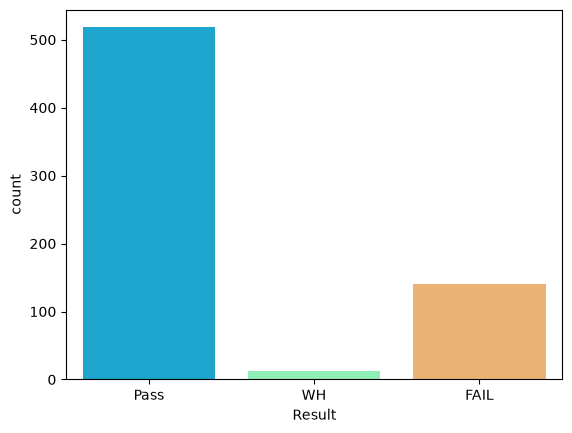

In [133]:
sns.countplot(x=df['Result'],palette='rainbow')

In [134]:
df['CPI']=df['CPI'].fillna(0.0)
df_fail = pd.DataFrame()

condition = (df['Result'] == 'FAIL') | (df['Result'] == 'WH')

df_fail['Name'] = df.loc[condition, 'Name']
df_fail['Result'] = df.loc[condition, 'Result']
df_fail['CPI'] = df.loc[condition, 'CPI']

df_fail.sort_values(by='CPI', ascending=True, ignore_index=True, inplace=True)

df_fail.to_csv('failed_students.csv', index=False)



In [135]:
df.sort_values(by='CPI',ascending=False)

,Semester,Specialisation,Scholar No,Name,SPI,CPI,College Rank,Result
410,II,Information Technology,25U030023,SURYANSH VERMA,10.00,9.93,1.0,Pass
411,II,Information Technology,25U030003,RIYA DWIVEDI,9.67,9.72,2.0,Pass
530,II,Electronics & Communication Engineering,25U010069,PREET SHUKLA,9.81,9.67,3.0,Pass
412,II,Information Technology,25U030092,JOYDIP PAL,9.29,9.60,4.0,Pass
0,II,Computer Science & Engineering,25U020130,ANUBHAV ARYA,9.52,9.60,4.0,Pass
...,...,...,...,...,...,...,...,...
173,I,Computer Science & Engineering,25U020154,LAKSH MITTAL,0.00,0.00,NaN,FAIL
622,I,Electronics & Communication Engineering,25U010084,AKASH P,0.00,0.00,NaN,FAIL
648,I,Mathematics and Computing,25U0404015,NAVDEEP,0.00,0.00,NaN,FAIL
649,I,Mathematics and Computing,25U0404026,ARMAN BEHERA,0.00,0.00,NaN,FAIL


<Axes: xlabel='count', ylabel='Specialisation'>

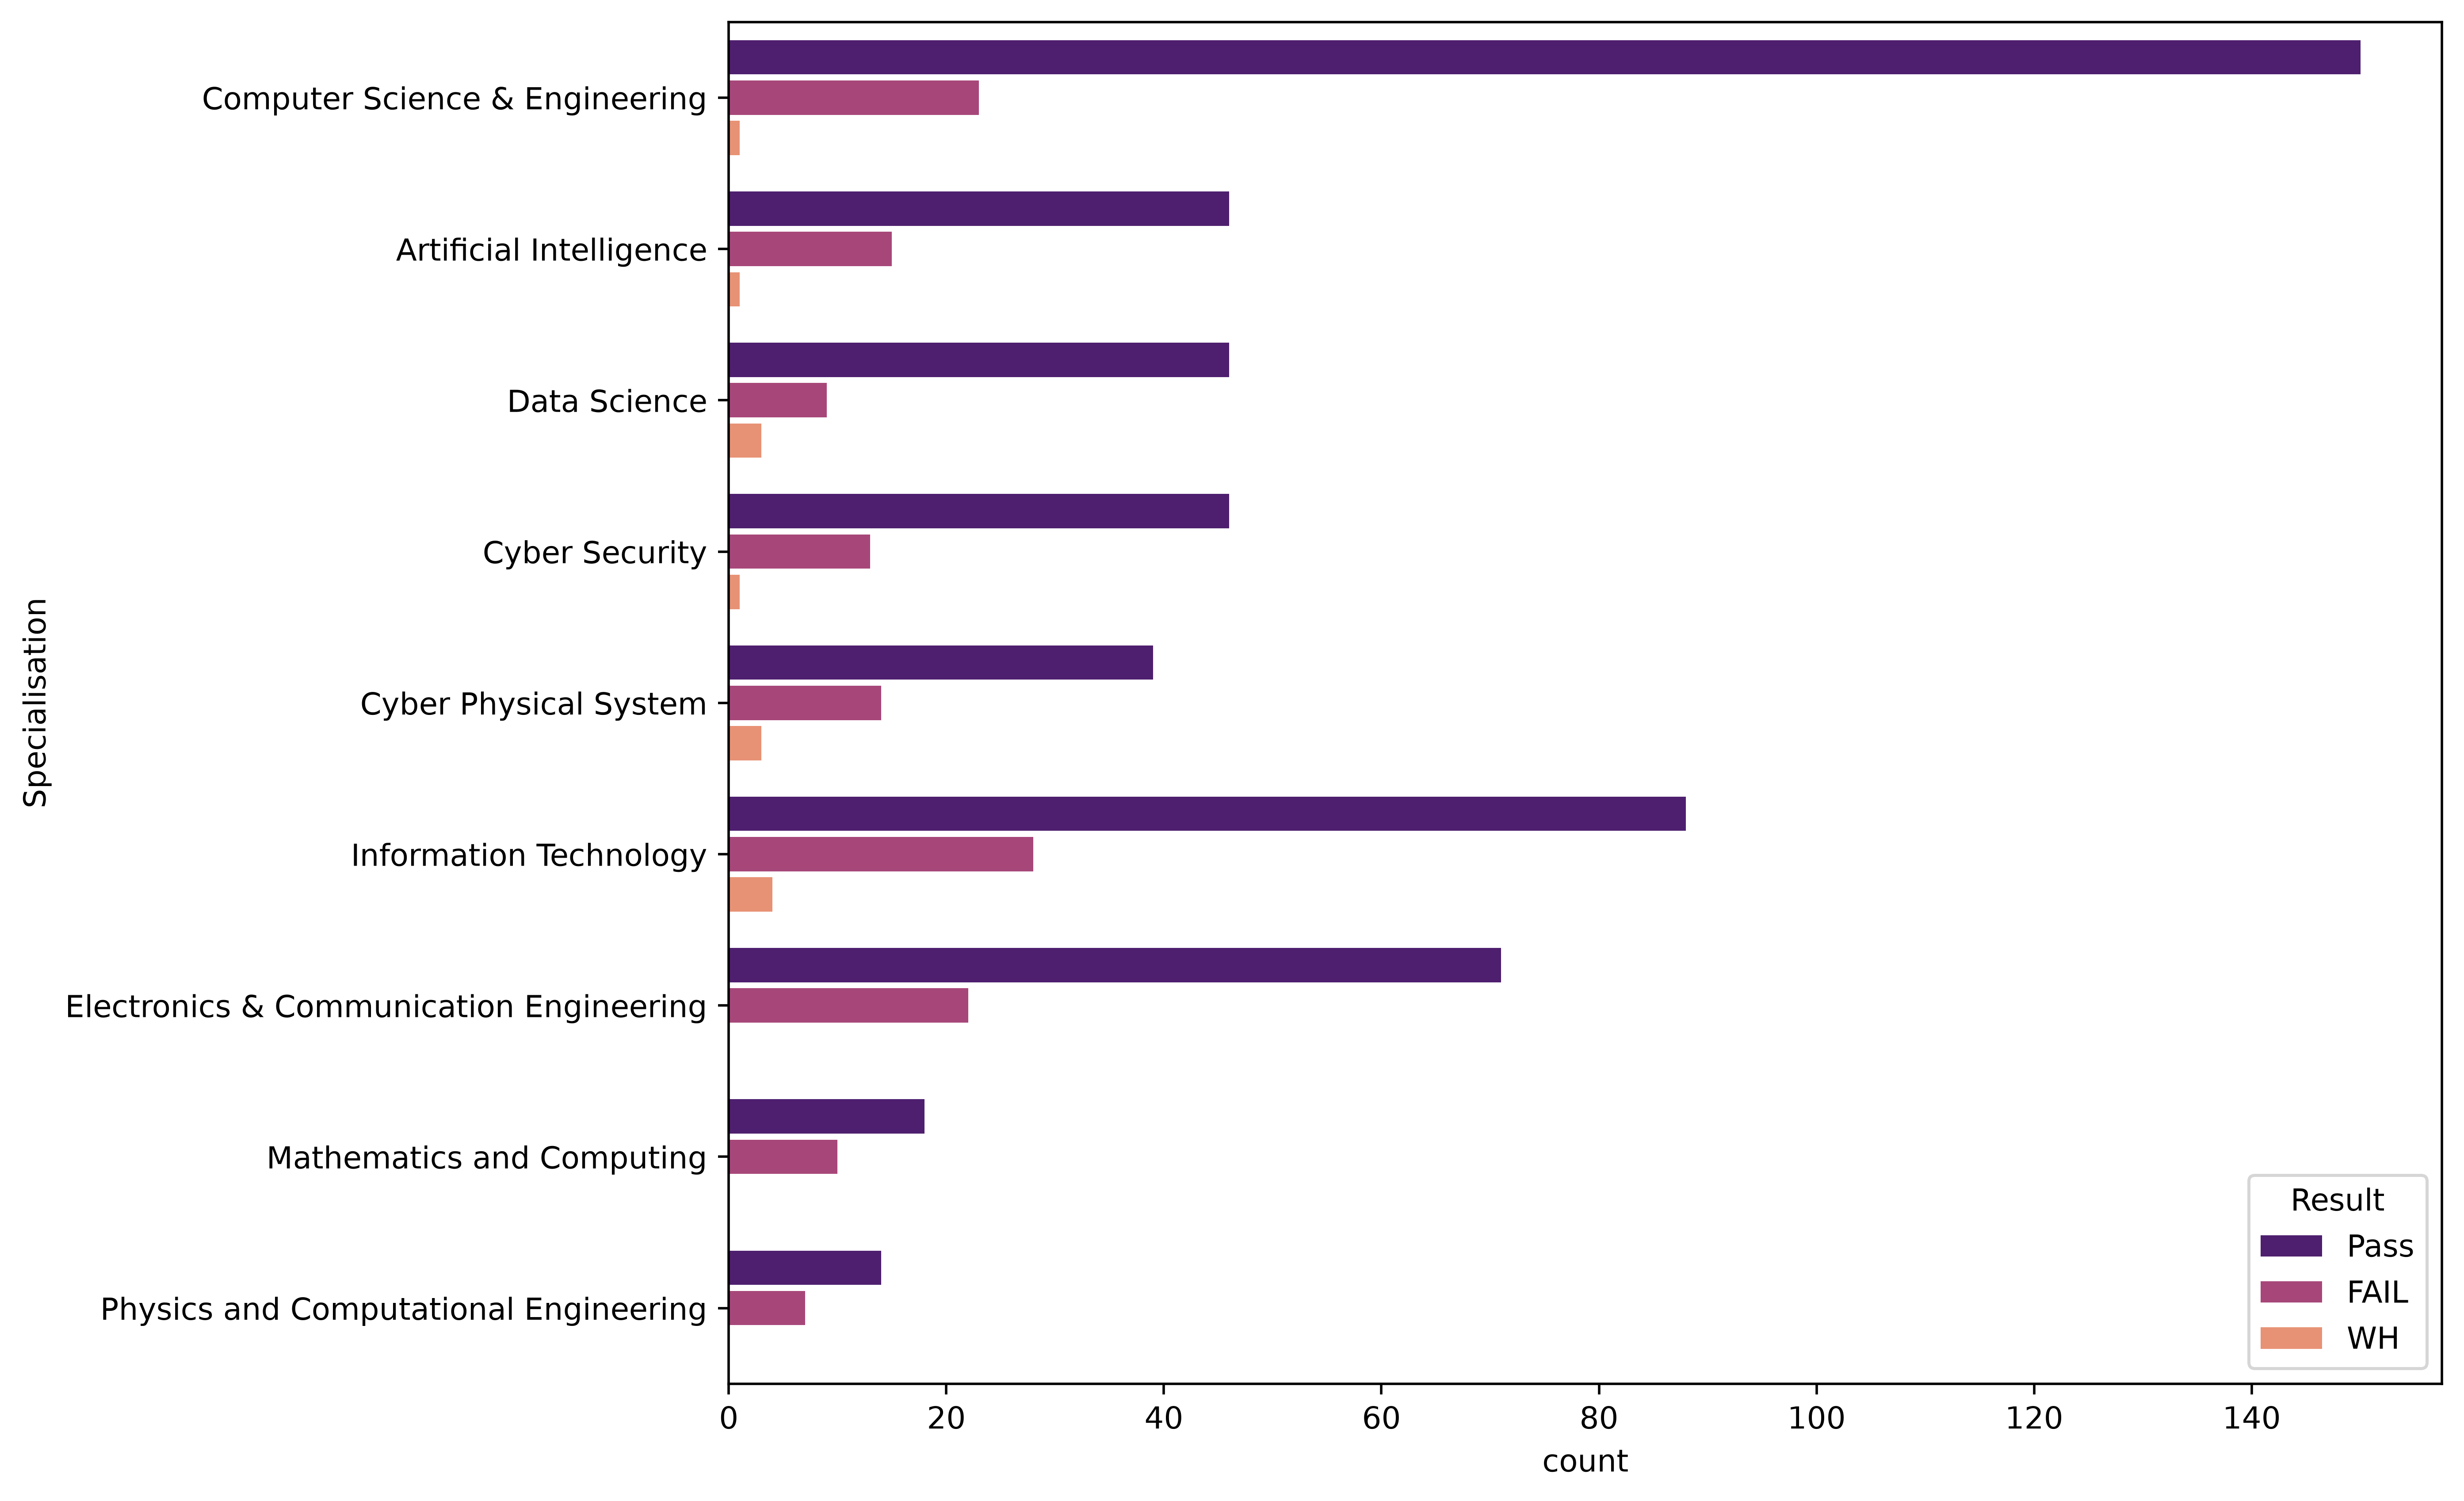

In [136]:
plt.figure(figsize=(10,8),dpi=500)
sns.countplot(data=df,y='Specialisation',hue='Result',palette='magma',gap=0.15,hue_order=['Pass','FAIL','WH'])


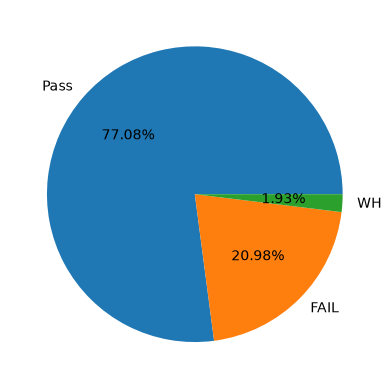

In [137]:
temp_df=pd.DataFrame()
temp_df['count']=df['Result'].value_counts()
temp_df
plt.pie(x=temp_df['count'],labels=temp_df.index,autopct='%1.2f%%')

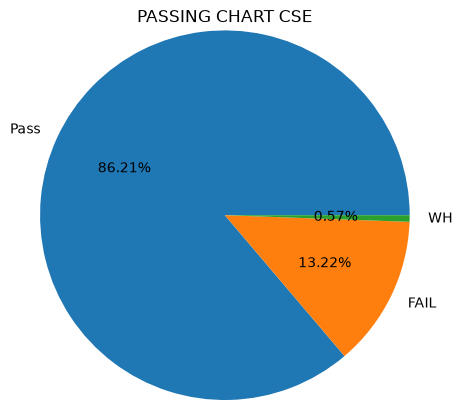

In [148]:
df_cse=pd.DataFrame()
df_cse['count']=df.loc[df['Specialisation']=='Computer Science & Engineering']['Result'].value_counts()
plt.title('PASSING CHART CSE')
plt.pie(x=df_cse['count'],labels=df_cse.index,autopct='%1.2f%%',radius=1.25)